In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

model_df = pd.read_csv("../data/processed/model_data.csv")
model_df.shape

(189, 17)

In [2]:
simple = smf.ols("log_P ~ a_High", data=model_df).fit()
simple.params

Intercept    6.837106
a_High      -2.200598
dtype: float64

In [3]:
simple.rsquared

np.float64(0.209570057721578)

In [4]:
multi = smf.ols("log_P ~ a_High + a_Low + np.log(R) + carry_share + after_2016", data=model_df).fit()
multi.params.round(3)

Intercept      9.998
a_High        -1.615
a_Low         -1.078
np.log(R)     -0.582
carry_share   -1.255
after_2016     0.643
dtype: float64

In [5]:
multi.rsquared

np.float64(0.5619038010240028)

In [6]:
np.exp(multi.params["after_2016"]) - 1

np.float64(0.9024565160172222)

In [7]:
multi.pvalues.round(4)

Intercept      0.0
a_High         0.0
a_Low          0.0
np.log(R)      0.0
carry_share    0.0
after_2016     0.0
dtype: float64

In [8]:
fe = smf.ols("log_P ~ a_High + a_Low + np.log(R) + carry_share + after_2016 + C(Region)", data=model_df).fit()
fe.params.round(3)

Intercept                           11.783
C(Region)[T.NSW Murray Above]        0.629
C(Region)[T.NSW Murray Below]        0.407
C(Region)[T.NSW Murrumbidgee]        0.567
C(Region)[T.SA Murray]              -0.607
C(Region)[T.VIC Goulburn-Broken]     0.166
C(Region)[T.VIC Loddon-Campaspe]     0.262
C(Region)[T.VIC Murray Above]        0.635
C(Region)[T.VIC Murray Below]        0.018
a_High                              -1.536
a_Low                               -1.326
np.log(R)                           -0.931
carry_share                         -1.492
after_2016                           0.647
dtype: float64

In [9]:
fe.rsquared

np.float64(0.6693151984432704)

In [10]:
np.exp(fe.params["after_2016"]) - 1

np.float64(0.9098618356349688)

In [11]:
fe_cl = smf.ols(
    "log_P ~ a_High + a_Low + np.log(R) + carry_share + after_2016 + C(Region)",
    data=model_df,
).fit(cov_type="cluster", cov_kwds={"groups": model_df["Year"]})

fe_cl.pvalues[["a_High", "a_Low", "np.log(R)", "carry_share", "after_2016"]].round(4)

a_High         0.0000
a_Low          0.0000
np.log(R)      0.0000
carry_share    0.0000
after_2016     0.0001
dtype: float64

## Results: panel regression

Dependent variable: log of the allocation price. Controls: high and low reliability
allocations, log rainfall, carryover share, and region fixed effects.

After 2016, prices are about **91% higher** at comparable water supply and weather
(coefficient 0.65, significant with year-clustered standard errors). 
     R² = 0.67.

In [12]:
from statsmodels.stats.anova import anova_lm

fe_int = smf.ols(
    "log_P ~ (a_High + a_Low + np.log(R) + carry_share) * after_2016 + C(Region)",
    data=model_df,
).fit()

anova_lm(fe, fe_int)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,175.0,63.022065,0.0,NaN,NaN,NaN
1,171.0,60.661165,4.0,2.3609,1.663807,0.160622


## Chow-type test: did the slopes change after 2016?

I compared the model with one set of slopes to a model with separate slopes
after 2016: F = 1.66, p = 0.16. There is no significant evidence that prices
respond differently to water supply and rainfall after 2016. What changed is the
level: at the same conditions, prices are about 90% higher.

Caveat: only 45 observations after 2016, so the test has limited power.

In [14]:
train = model_df[model_df["Year"] <= 2016]
test = model_df[model_df["Year"] >= 2017].copy()

oos = smf.ols("log_P ~ a_High + a_Low + np.log(R) + carry_share + C(Region)", data=train).fit()
oos.rsquared

np.float64(0.6859267363123088)

In [15]:
test["pred_log_P"] = oos.predict(test)

gap = (test["log_P"] - test["pred_log_P"]).mean()
np.exp(gap) - 1

np.float64(0.9087076593438659)

In [16]:
correction = np.exp(oos.resid).mean()
test["pred_P"] = np.exp(test["pred_log_P"]) * correction

by_year = test.groupby("Year")[["P", "pred_P"]].mean()
by_year.round(0)

,P,pred_P
Year,,
2017,75.0,62.0
2018,125.0,101.0
2019,401.0,218.0
2020,526.0,204.0
2021,133.0,105.0


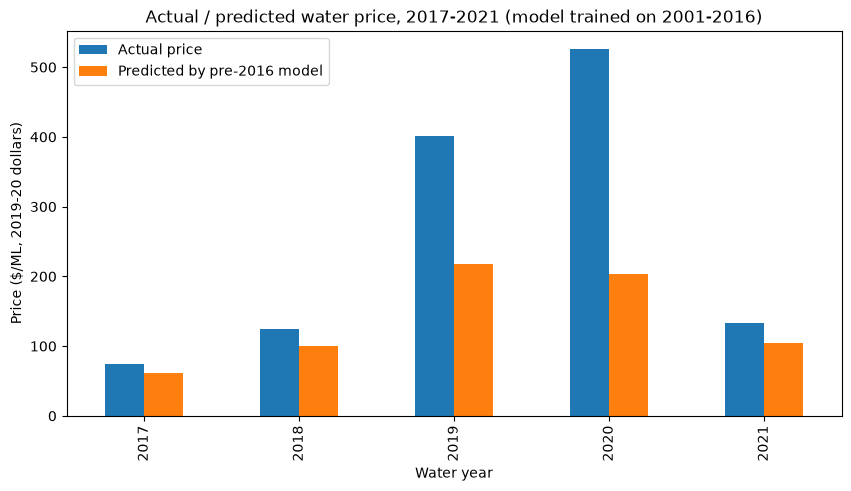

In [18]:
ax = by_year.plot(kind="bar", figsize=(10, 5))
ax.set_title("Actual / predicted water price, 2017-2021 (model trained on 2001-2016)")
ax.set_xlabel("Water year")
ax.set_ylabel("Price ($/ML, 2019-20 dollars)")
ax.legend(["Actual price", "Predicted by pre-2016 model"]);

## Out-of-sample test

I trained the panel model on 2001-2016 only and used it to predict 2017-2021 prices.
Actual prices were on average about **91% higher** than predicted, the same magnitude
as the post-2016 coefficient. The gap is largest in the 2019 and 2020 drought years.

Dollar predictions include a correction for the log transformation (smearing factor).

In [19]:
fe_eff = smf.ols(
    "log_P ~ eff_High + eff_Low + np.log(R) + carry_share + after_2016 + C(Region)",
    data=model_df,
).fit()

np.exp(fe_eff.params["after_2016"]) - 1

np.float64(0.5649292160067381)

In [20]:
share = 1 - fe_eff.params["after_2016"] / fe.params["after_2016"]
share

np.float64(0.30785285193926826)